# 15 - LOH.1 with receivers above and below the source (ShakerMaker vs SW4)

The **SCEC LOH.1** model (a 1 km slow layer over a half-space, a vertical strike-slip point source at
2 km depth) is used here with receivers **at depth, above and below the source**, and the
ShakerMaker (FK) result is compared with **SW4** (4th-order finite differences) for the same model,
source and receivers.

**Why this example.** When a receiver is deeper than the source, the FK core (`subgreen.f`,
`subgreen2.f`, `subrt.f`) turns the layered model upside down so that the receiver is above the source
(the *flip* of Zhu's `fk.f`). Until this fix the reversal was written as `d=d(mb:1:-1)` on arrays
declared with `nlay = 2000` elements, which wrote past the end of the model and crashed the run.
SW4 has no flip and no wavenumber integral, so it is an independent reference for the receivers
below the source.

**What is checked.**
1. The receivers below the source give the same seismograms as SW4 (shape and amplitude).
2. The receivers just above and just below the source are consistent.
3. The sensitivity of the receivers 0.5 km from the source depth to the wavenumber cut-off `kc`.

Files used: `../receivers.txt` (receiver list), `../loh1_below_source.in` (SW4 input),
`../data/sw4/` (SW4 output and run log), `../data/sm/` (ShakerMaker reference output).

In [1]:
import os
import contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

from shakermaker import shakermaker
from shakermaker.cm_library.LOH import SCEC_LOH_1
from shakermaker.pointsource import PointSource
from shakermaker.faultsource import FaultSource
from shakermaker.station import Station
from shakermaker.stationlist import StationList
from shakermaker.stf_extensions.gaussian import Gaussian

HERE = os.path.abspath("..")
SW4_DIR = os.path.join(HERE, "data", "sw4")
print("example folder:", HERE)


    ▄████████     ▄█    █▄     ▄████████     ▄█   ▄█▄    ▄████████    ▄████████
    ███    ███   ███    ███    ███    ███    ███ ▄███▀   ███    ███   ███    ███
    ███    █▀    ███    ███    ███    ███    ███▐██▀     ███    █▀    ███    ███
    ███         ▄███▄▄▄▄███▄▄  ███    ███   ▄█████▀     ▄███▄▄▄      ▄███▄▄▄▄██▀
  ▀███████████  ▀███▀▀▀▀███▀  ▀███████████  ▀█████▄    ▀▀███▀▀▀     ▀▀███▀▀▀▀▀
           ███   ███    ███    ███    ███    ███▐██▄     ███    █▄   ▀███████████
     ▄█    ███   ███    ███    ███    ███    ███ ▀███▄   ███    ███   ███    ███
   ▄████████▀    ███    █▀     ███    █▀     ███   ▀█▀   ██████████   ███    ███
                                                                      ███    ███

         ▄▄▄▄███▄▄▄▄      ▄████████    ▄█   ▄█▄    ▄████████    ▄████████
       ▄██▀▀▀███▀▀▀██▄   ███    ███    ███ ▄███▀   ███    ███   ███    ███
       ███   ███   ███   ███    ███    ███▐██▀     ███    █▀    ███    ███
       ███   ███   ███   ███    ███   ▄█████▀  

## Model, source and receivers

Same crust, source and FK parameters as `12_validation/LOH1.py`, which is validated against the
Prose solution at the surface receiver (6, 8, 0) km. Ten receivers on two verticals:

- **(6, 8) km**, 10 km from the epicentre (the LOH.1 receiver): surface, 1.5 km (0.5 km above the
  source) and 2.5, 3, 4 and 6 km (0.5 to 4 km below the source);
- **(0.6, 0.8) km**, 1 km from the epicentre (station `sta01` of the SW4 example): surface, 1.5, 2.5
  and 4 km.

Coordinates are in km from the epicentre: x north, y east, z depth (positive down).

In [2]:
rows = [l.split() for l in open(os.path.join(HERE, "receivers.txt")) if l.strip() and not l.startswith("#")]
receivers = pd.DataFrame(rows, columns=["name", "north_km", "east_km", "depth_km"]).astype(
    {"north_km": float, "east_km": float, "depth_km": float})
receivers["position"] = np.where(receivers.depth_km > 2.0, "below the source", "above the source")
receivers

,name,north_km,east_km,depth_km,position
0,o6_z0000,6.0,8.0,0.0,above the source
1,o6_z1500,6.0,8.0,1.5,above the source
2,o6_z2500,6.0,8.0,2.5,below the source
3,o6_z3000,6.0,8.0,3.0,below the source
4,o6_z4000,6.0,8.0,4.0,below the source
5,o6_z6000,6.0,8.0,6.0,below the source
6,o06_z0000,0.6,0.8,0.0,above the source
7,o06_z1500,0.6,0.8,1.5,above the source
8,o06_z2500,0.6,0.8,2.5,below the source
9,o06_z4000,0.6,0.8,4.0,below the source


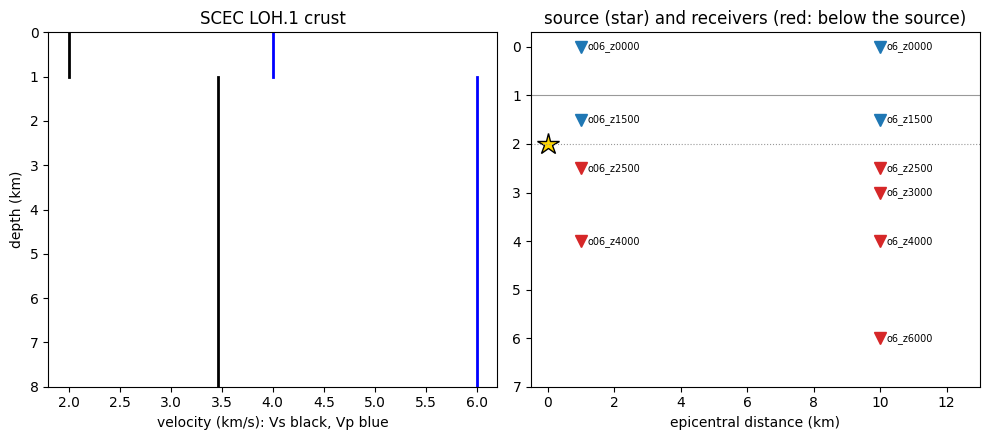

In [3]:
crust = SCEC_LOH_1()
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
top = 0.0
for i in range(crust.nlayers):
    bot = top + crust.d[i] if crust.d[i] > 0 else 8.0
    ax[0].plot([crust.b[i], crust.b[i]], [top, bot], "k", lw=2)
    ax[0].plot([crust.a[i], crust.a[i]], [top, bot], "b", lw=2)
    top = bot
ax[0].set_ylim(8, 0); ax[0].set_xlabel("velocity (km/s): Vs black, Vp blue"); ax[0].set_ylabel("depth (km)")
ax[0].set_title("SCEC LOH.1 crust")
for _, r in receivers.iterrows():
    hd = np.hypot(r.north_km, r.east_km)
    ax[1].plot(hd, r.depth_km, "v", color="tab:red" if r.depth_km > 2 else "tab:blue", ms=9)
    ax[1].text(hd + 0.2, r.depth_km, r["name"], fontsize=7, va="center")
ax[1].plot(0, 2.0, "*", color="gold", mec="k", ms=16)
ax[1].axhline(1.0, color="0.6", lw=0.8); ax[1].axhline(2.0, color="0.6", ls=":", lw=0.8)
ax[1].set_ylim(7, -0.3); ax[1].set_xlim(-0.5, 13); ax[1].set_xlabel("epicentral distance (km)")
ax[1].set_title("source (star) and receivers (red: below the source)")
fig.tight_layout(); fig.savefig("model_and_receivers.png", dpi=130)

## Run ShakerMaker

All ten receivers in one run (a few seconds). The receivers deeper than the source go through the
flipped-model path of the core.

In [4]:
sigma = 0.06
src = PointSource([0, 0, 2.0], [0., 90., 0.],
                  stf=Gaussian(t0=6 * sigma, freq=1 / sigma, M0=1e18 / 5e14 / 2, derivative=False))
fault = FaultSource([src], metadata={"name": "LOH1_source"})
stations = [Station([r.north_km, r.east_km, r.depth_km], metadata={"name": r["name"]}) for _, r in receivers.iterrows()]
model = shakermaker.ShakerMaker(crust, fault, StationList(stations, {}))
with contextlib.redirect_stdout(io.StringIO()):
    model.run(dt=0.025, nfft=4096, tb=1000, dk=0.1, tmax=4096 * 0.025, smth=1)
sm_raw = {}
for sta in stations:
    z, e, n, t = sta.get_response()
    assert np.all(np.isfinite(z)) and np.all(np.isfinite(e)) and np.all(np.isfinite(n))
    sm_raw[sta.metadata["name"]] = dict(Z=z, E=e, N=n, t=t)
print("finite responses for", len(sm_raw), "receivers")

finite responses for 10 receivers


## SW4 reference

`../loh1_below_source.in`: the LOH.1 material (Vp 6, Vs 3.464 km/s, density 2.7 below 1 km; Vp 4,
Vs 2, density 2.6 above), the same moment tensor (`mxy = 1e18` N m, Gaussian, `t0 = 0.36 s`,
`freq = 16.6667`) at (12, 12, 2) km in a 24 x 24 x 12 km domain, grid h = 100 m refined to 50 m in
the 1 km layer, 9 s of simulation, supergrid absorbing layers. It ran with 4 MPI ranks in about 25
minutes. SW4 reports the bandwidth that the grid resolves in the header of every receiver file:

In [5]:
print("".join(l for l in open(os.path.join(SW4_DIR, "o6_z0000.txt")) if l.startswith("#"))[:900])
print([l.strip() for l in open(os.path.join(SW4_DIR, "sw4_run_log.txt")) if "number of grid points" in l or "Number of time steps" in l])

# Author: SW4
# Scenario: test
# Date: UTC  10/19/2026:22:22:11.000
# Bandwith (Hz): 1.234000e+00
# Station: o6_z0000
# Target location (WGS84 longitude, latitude) (deg): -1.177746e+02 3.716170e+01
# Actual location (WGS84 longitude, latitude) (deg): -1.177746e+02 3.716170e+01
# Distance from target to actual location (m): 0.000000e+00
# nColumns: 4
# Column 1: Time (s)
# Column 2: X velocity (m/s)
# Column 3: Y velocity (m/s)
# Column 4: Z velocity (m/s)

['Total number of grid points (without ghost points): 1.13056e+07', 'Number of time steps = 678 dt: 0.0132743']


**Comparison band: 0.1-1.2 Hz**, inside the 1.234 Hz that SW4 resolves; window: the 9 s that SW4
simulates.

**Source time function convention.** The two codes define the Gaussian differently. With
`Gaussian(derivative=False)` the ShakerMaker output equals the **time integral of the SW4 velocity**
for `type=Gaussian`. The surface receiver shows it (correlation with SW4, the time derivative of SW4
and the time integral of SW4):

In [6]:
DT, TMAX, FMIN, FMAX = 0.01, 9.0, 0.1, 1.2
tc = np.arange(0.0, TMAX, DT)
sos = butter(4, [FMIN, FMAX], btype="band", fs=1 / DT, output="sos")

def sw4_velocity(name):
    a = np.loadtxt(os.path.join(SW4_DIR, f"{name}.txt"), comments="#")
    return a[:, 0], {"N": a[:, 1], "E": a[:, 2], "Z": a[:, 3]}       # x north, y east, z

t4, v4 = sw4_velocity("o6_z0000")
check = []
for k in "ZEN":
    x = sosfiltfilt(sos, np.interp(tc, sm_raw["o6_z0000"]["t"], sm_raw["o6_z0000"][k]))
    y = np.interp(tc, t4, v4[k])
    for label, yy in (("SW4", y), ("d/dt SW4", np.gradient(y, DT)), ("integral of SW4", np.cumsum(y) * DT)):
        check.append(dict(component=k, compared_with=label, cc=np.corrcoef(x, sosfiltfilt(sos, yy))[0, 1]))
pd.DataFrame(check).pivot(index="compared_with", columns="component", values="cc").round(3)

component,E,N,Z
compared_with,,,
SW4,-0.056,-0.065,-0.071
d/dt SW4,-0.763,-0.807,-0.937
integral of SW4,0.995,0.991,0.995


So the SW4 velocity is integrated in time (cumulative trapezoid) before the comparison. The z
components of both outputs have the same sign. One amplitude factor (ShakerMaker LOH.1 units to SW4
units) is fitted at the surface receiver `o6_z0000` and then **applied to every receiver**, so the
amplitudes at depth are compared too.

In [7]:
def sw4_disp(name):
    t, v = sw4_velocity(name)
    out = {}
    for k, x in v.items():
        u = np.concatenate([[0.0], np.cumsum(0.5 * (x[1:] + x[:-1]) * np.diff(t))])
        out[k] = sosfiltfilt(sos, np.interp(tc, t, u))
    return out

sw4 = {n: sw4_disp(n) for n in receivers.name}
sm = {n: {k: sosfiltfilt(sos, np.interp(tc, d["t"], d[k])) for k in "ZEN"} for n, d in sm_raw.items()}
ref = "o6_z0000"
scale = sum(sm[ref][k] @ sw4[ref][k] for k in "ZEN") / sum(sm[ref][k] @ sm[ref][k] for k in "ZEN")
print(f"amplitude factor fitted at {ref}: {scale:.5f}")

table = []
for _, r in receivers.iterrows():
    row = dict(receiver=r["name"], depth_km=r.depth_km, epicentral_km=np.hypot(r.north_km, r.east_km), position=r.position)
    for k in "ZEN":
        a, b = sw4[r["name"]][k], scale * sm[r["name"]][k]
        row[f"cc {k}"] = np.corrcoef(a, b)[0, 1]
        row[f"peak {k}"] = np.abs(b).max() / np.abs(a).max()
        row[f"nrms {k}"] = np.linalg.norm(b - a) / np.linalg.norm(a)
    table.append(row)
table = pd.DataFrame(table)
table.to_csv("comparison.csv", index=False)
table.round(3)

amplitude factor fitted at o6_z0000: 0.97789


,receiver,depth_km,epicentral_km,position,cc Z,peak Z,nrms Z,cc E,peak E,nrms E,cc N,peak N,nrms N
0,o6_z0000,0.0,10.0,above the source,0.997,1.005,0.085,0.997,0.959,0.084,0.993,0.968,0.122
1,o6_z1500,1.5,10.0,above the source,0.995,1.045,0.116,0.999,0.966,0.047,0.998,0.993,0.069
2,o6_z2500,2.5,10.0,below the source,0.997,0.975,0.081,0.999,0.971,0.042,0.999,0.986,0.048
3,o6_z3000,3.0,10.0,below the source,0.999,0.966,0.044,1.000,0.972,0.028,1.000,0.984,0.028
4,o6_z4000,4.0,10.0,below the source,1.000,0.974,0.028,1.000,0.973,0.029,1.000,0.983,0.024
5,o6_z6000,6.0,10.0,below the source,1.000,0.979,0.037,1.000,0.974,0.039,1.000,0.972,0.036
6,o06_z0000,0.0,1.0,above the source,0.981,1.045,0.200,0.949,1.075,0.333,0.977,1.023,0.214
7,o06_z1500,1.5,1.0,above the source,0.995,1.052,0.111,0.997,0.959,0.083,0.997,0.959,0.086
8,o06_z2500,2.5,1.0,below the source,0.997,0.976,0.084,0.997,0.978,0.075,0.997,0.984,0.076
9,o06_z4000,4.0,1.0,below the source,1.000,0.991,0.029,0.995,1.017,0.106,0.998,0.990,0.057


*cc*: zero-lag correlation; *peak*: ShakerMaker peak / SW4 peak; *nrms*: norm of the difference / norm
of SW4. All in 0.1-1.2 Hz, displacement-equivalent, first 9 s.

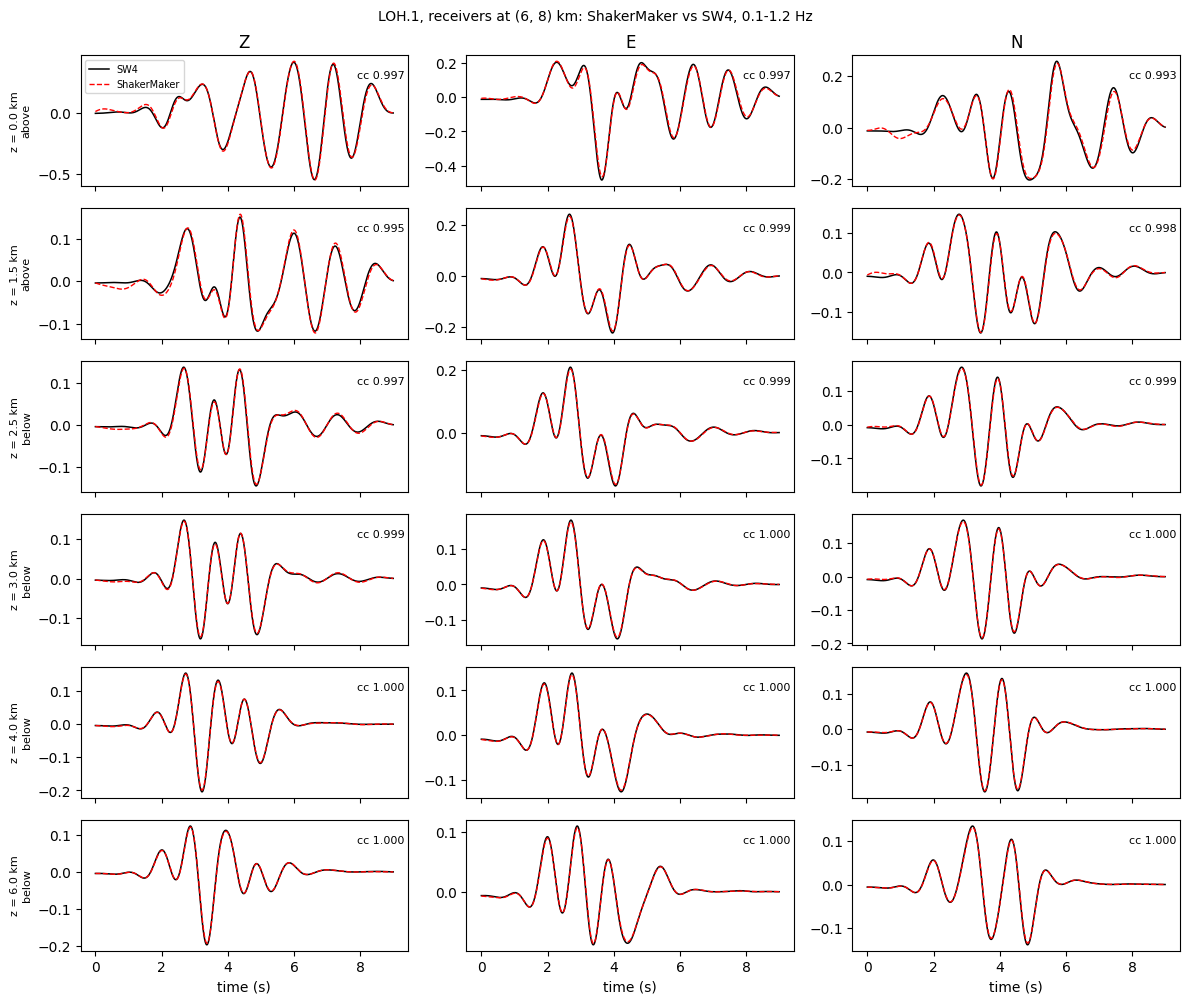

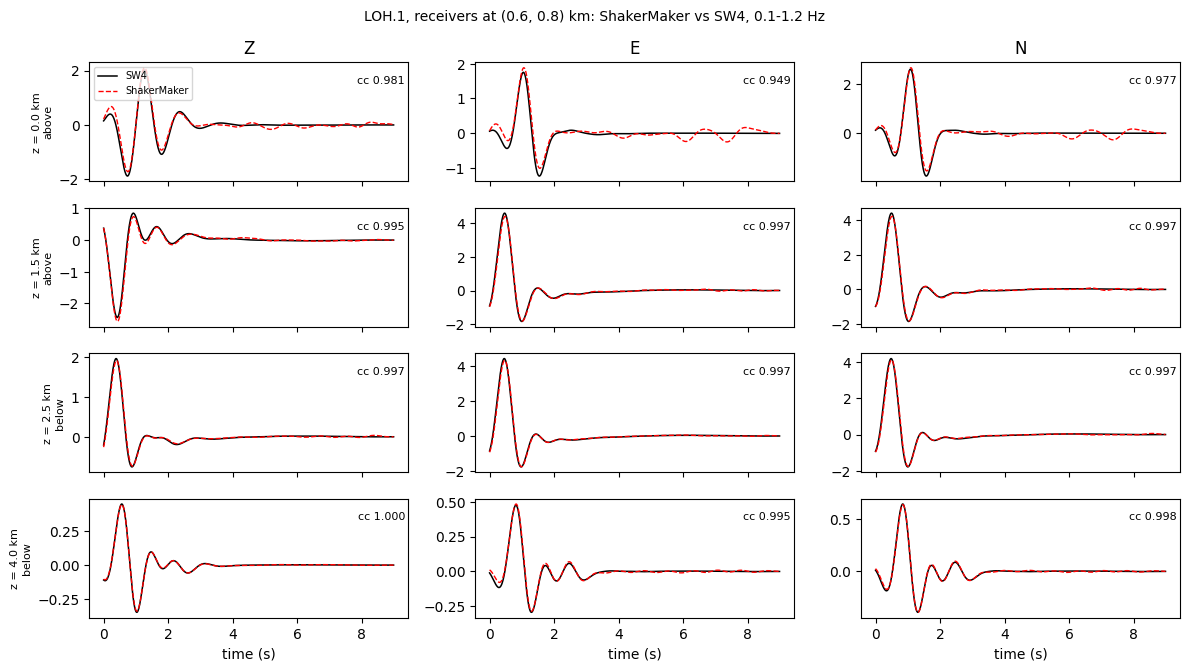

In [8]:
for vertical, title in (("o6_", "receivers at (6, 8) km"), ("o06_", "receivers at (0.6, 0.8) km")):
    names = [n for n in receivers.name if n.startswith(vertical)]
    fig, axes = plt.subplots(len(names), 3, figsize=(12, 1.7 * len(names)), sharex=True)
    for i, n in enumerate(names):
        dep = float(receivers.set_index("name").loc[n, "depth_km"])
        for j, k in enumerate("ZEN"):
            ax = axes[i, j]
            ax.plot(tc, sw4[n][k], "k", lw=1.1, label="SW4")
            ax.plot(tc, scale * sm[n][k], "r--", lw=1.0, label="ShakerMaker")
            ax.text(0.99, 0.82, f"cc {table.set_index('receiver').loc[n, 'cc ' + k]:.3f}", transform=ax.transAxes, ha="right", fontsize=8)
            if i == 0: ax.set_title(k)
            if j == 0: ax.set_ylabel(f"z = {dep} km\n{'below' if dep > 2 else 'above'}", fontsize=8)
    axes[0, 0].legend(fontsize=7, loc="upper left")
    for ax in axes[-1]: ax.set_xlabel("time (s)")
    fig.suptitle(f"LOH.1, {title}: ShakerMaker vs SW4, 0.1-1.2 Hz", fontsize=10)
    fig.tight_layout(); fig.savefig(f"traces_{vertical.strip('_')}.png", dpi=120)

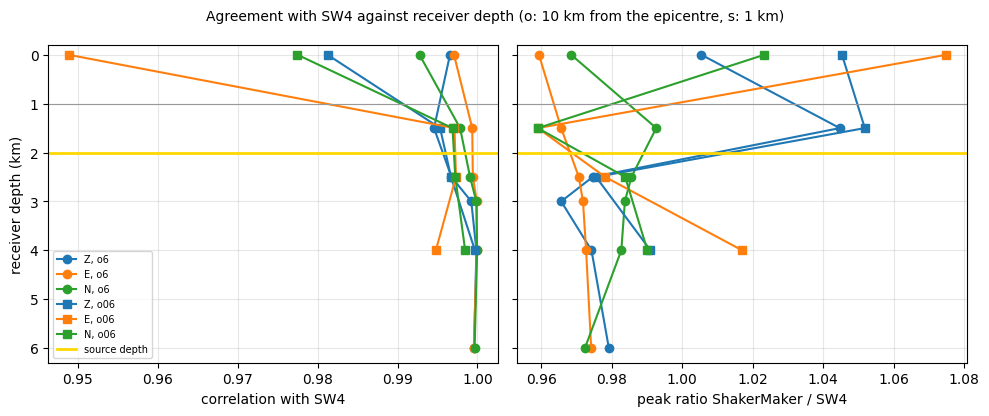

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for vertical, mk in (("o6_", "o"), ("o06_", "s")):
    sub = table[table.receiver.str.startswith(vertical)]
    for k, col in zip("ZEN", ("tab:blue", "tab:orange", "tab:green")):
        ax[0].plot(sub[f"cc {k}"], sub.depth_km, mk + "-", color=col, label=f"{k}, {vertical.strip('_')}")
        ax[1].plot(sub[f"peak {k}"], sub.depth_km, mk + "-", color=col)
for a in ax:
    a.axhline(2.0, color="gold", lw=2, label="source depth"); a.axhline(1.0, color="0.6", lw=0.8); a.grid(alpha=0.3)
ax[0].set_ylim(6.3, -0.2); ax[0].set_ylabel("receiver depth (km)")
ax[0].set_xlabel("correlation with SW4"); ax[1].set_xlabel("peak ratio ShakerMaker / SW4")
ax[0].legend(fontsize=7)
fig.suptitle("Agreement with SW4 against receiver depth (o: 10 km from the epicentre, s: 1 km)", fontsize=10)
fig.tight_layout(); fig.savefig("agreement_vs_depth.png", dpi=130)

## The receivers 0.5 km from the source depth: wavenumber cut-off

The FK kernels decay with wavenumber like exp(-k dz), with dz the source-receiver depth separation,
so receivers close to the source depth need a high maximum wavenumber. `subfk.f` cuts the integral
at `kc / hs`. `subgreen` passes `hs` = the source-receiver separation, as Zhu's `fk.f` does; it used
to pass the total thickness of the layered model, and then `o06_z2500` (1 km from the epicentre,
0.5 km below the source) had a peak ratio of 1.36 on Z with the default `kc = 15` and needed
`kc >= 30`. Rerunning the three receivers at dz = 0.5 km with a larger `kc` checks that the result is
now converged (`../kc_check.py` does the same for kc = 15, 30, 60, 150):

In [10]:
kc_rows = []
for n in ("o06_z1500", "o06_z2500", "o6_z2500"):
    r = receivers.set_index("name").loc[n]
    for kc in (15.0, 30.0, 60.0):
        sta = Station([r.north_km, r.east_km, r.depth_km], metadata={"name": n})
        m = shakermaker.ShakerMaker(SCEC_LOH_1(), FaultSource([PointSource([0, 0, 2.0], [0., 90., 0.],
                stf=Gaussian(t0=0.36, freq=1 / 0.06, M0=1e18 / 5e14 / 2, derivative=False))], metadata={"name": "s"}),
                StationList([sta], {}))
        with contextlib.redirect_stdout(io.StringIO()):
            m.run(dt=0.025, nfft=4096, tb=1000, dk=0.1, kc=kc, tmax=4096 * 0.025, smth=1)
        z, e, nn, t = sta.get_response()
        resp = {"Z": z, "E": e, "N": nn}
        row = dict(receiver=n, position=r.position, kc=kc)
        for k in "ZEN":
            a, b = sw4[n][k], scale * sosfiltfilt(sos, np.interp(tc, t, resp[k]))
            row[f"peak {k}"] = np.abs(b).max() / np.abs(a).max()
            row[f"nrms {k}"] = np.linalg.norm(b - a) / np.linalg.norm(a)
            if n == "o06_z2500" and k == "Z":
                row["_trace"] = b
        kc_rows.append(row)
kc_table = pd.DataFrame(kc_rows)
kc_table.drop(columns=["_trace"]).to_csv("kc_check.csv", index=False)
kc_table.drop(columns=["_trace"]).round(3)

,receiver,position,kc,peak Z,nrms Z,peak E,nrms E,peak N,nrms N
0,o06_z1500,above the source,15.0,1.052,0.111,0.959,0.083,0.959,0.086
1,o06_z1500,above the source,30.0,1.052,0.111,0.959,0.083,0.959,0.086
2,o06_z1500,above the source,60.0,1.052,0.111,0.959,0.083,0.959,0.086
3,o06_z2500,below the source,15.0,0.976,0.084,0.978,0.075,0.984,0.076
4,o06_z2500,below the source,30.0,0.976,0.084,0.978,0.075,0.984,0.076
5,o06_z2500,below the source,60.0,0.976,0.084,0.978,0.075,0.984,0.076
6,o6_z2500,below the source,15.0,0.975,0.081,0.971,0.042,0.986,0.048
7,o6_z2500,below the source,30.0,0.975,0.081,0.971,0.042,0.986,0.048
8,o6_z2500,below the source,60.0,0.975,0.081,0.971,0.042,0.986,0.048


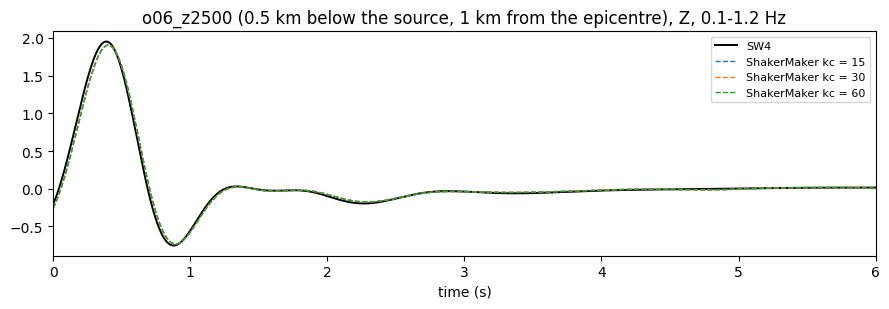

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(tc, sw4["o06_z2500"]["Z"], "k", lw=1.4, label="SW4")
for _, r in kc_table[kc_table.receiver == "o06_z2500"].iterrows():
    ax.plot(tc, r["_trace"], "--", lw=1.0, label=f"ShakerMaker kc = {r.kc:.0f}")
ax.set_xlim(0, 6); ax.set_xlabel("time (s)"); ax.legend(fontsize=8)
ax.set_title("o06_z2500 (0.5 km below the source, 1 km from the epicentre), Z, 0.1-1.2 Hz")
fig.tight_layout(); fig.savefig("kc_o06_z2500.png", dpi=130)

## Conclusions

1. **Receivers below the source:** the flipped-model path gives the same seismograms as SW4: at 1 to 4
   km below the source the correlation is 0.995-1.000 and the peak ratio 0.97-1.02 on the three
   components, at both epicentral distances, with the amplitude factor fitted only at the surface.
2. **Receivers 0.5 km above and below the source** agree with SW4 as well as the surface receiver
   does (correlation 0.995-0.999), at both epicentral distances.
3. **Wavenumber cut-off:** with the cut-off based on the source-receiver separation the receivers
   0.5 km from the source depth are converged in `kc` (15, 30 and 60 give the same seismograms).
   With the previous cut-off (total model thickness) the vertical component 0.5 km below the source
   near the epicentre had a peak ratio of 1.36 with `kc = 15`.
4. The surface receiver 1 km from the epicentre (`o06_z0000`) shows the largest difference of the
   set (correlation 0.95-0.98): it sits in the near field of the source, where the SW4 grid
   (h = 100 m) is coarsest relative to the wavefield.